In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import ceil, log10
from collections import deque
np.set_printoptions(precision=4, suppress=True)

,availability,seed,immediate_delivered,immediate_lost,sf_on_time,sf_delayed,sf_lost,sf_mean_delay_min
0,0.3,1049.5,303.64,696.36,251.76,632.86,115.38,25.60
1,0.6,1049.5,604.96,395.04,587.18,409.45,3.37,6.67
2,0.9,1049.5,900.53,99.47,900.53,99.30,0.17,1.11


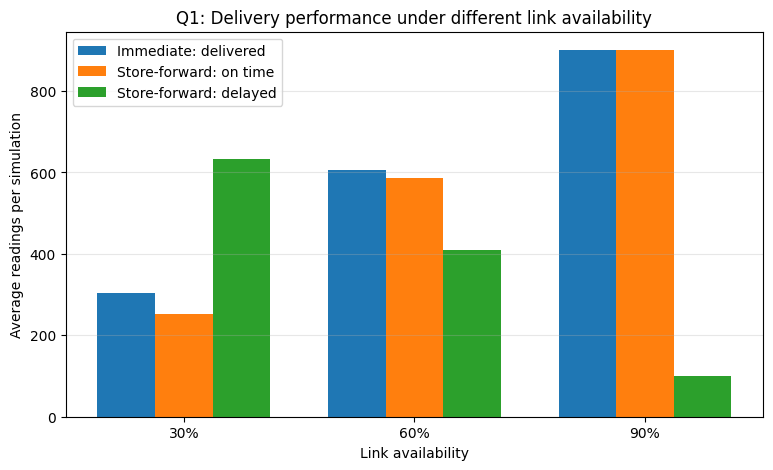

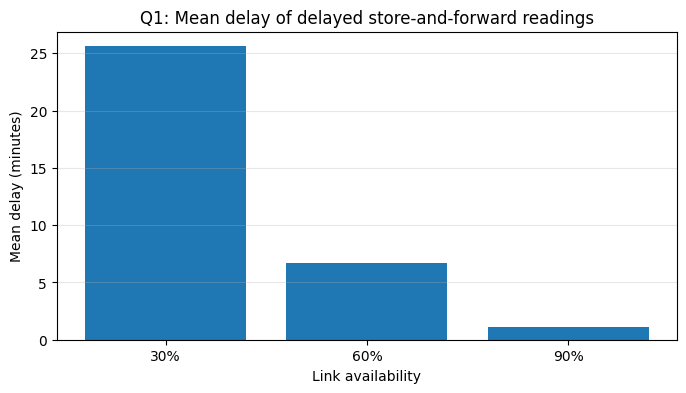

In [5]:
# One reading per minute. Compare immediate send with FIFO store-and-forward.
def make_bursty_link(T, p, rng, mean_up=10):
    # Two-state Markov chain with stationary P(UP)=p and mean UP run=mean_up.
    p_down_to_up = 1.0 / (mean_up * (1-p) / p) if p < 1 else 1.0
    p_up_to_down = 1.0 / mean_up
    link = np.zeros(T, dtype=bool)
    state = rng.random() < p
    for t in range(T):
        link[t] = state
        if state and rng.random() < p_up_to_down:
            state = False
        elif not state and rng.random() < p_down_to_up:
            state = True
    return link

def q1_run(p, seed, T=1000, buffer_size=50, upload_per_tick=10):
    rng = np.random.default_rng(seed)
    link = make_bursty_link(T, p, rng)
    # Immediate strategy
    immediate_on_time = int(link.sum())
    immediate_lost = T - immediate_on_time

    # Store-forward queue. Reading IDs are their generation tick.
    queue = deque()
    delayed_delays = []
    on_time = delayed = lost = 0
    for t in range(T):
        if len(queue) >= buffer_size:
            lost += 1
        else:
            queue.append(t)
        if link[t]:
            for _ in range(min(upload_per_tick, len(queue))):
                created = queue.popleft()
                if created == t:
                    on_time += 1
                else:
                    delayed += 1
                    delayed_delays.append(t-created)
    lost += len(queue)  # unfinished at end of experiment
    # Correct on-time count: count delivered readings with zero delay.
    # The queue may send the current reading in the same tick.
    return {
        "availability": p, "seed": seed,
        "immediate_delivered": immediate_on_time, "immediate_lost": immediate_lost,
        "sf_on_time": on_time, "sf_delayed": delayed, "sf_lost": lost,
        "sf_mean_delay_min": float(np.mean(delayed_delays)) if delayed_delays else 0.0
    }

q1_rows = []
for p in (0.9, 0.6, 0.3):
    for seed in range(1000, 1100):
        q1_rows.append(q1_run(p, seed))
q1 = pd.DataFrame(q1_rows)
q1_summary = q1.groupby("availability").mean(numeric_only=True).reset_index()
display(q1_summary.round(2))
q1.to_csv("q1_results.csv", index=False)
q1_summary.to_csv("q1_summary.csv", index=False)

# Visualisation: immediate delivery versus store-and-forward
q1_plot = q1_summary.sort_values("availability")
x = np.arange(len(q1_plot))
width = 0.25
plt.figure(figsize=(9,5))
plt.bar(x-width, q1_plot["immediate_delivered"], width, label="Immediate: delivered")
plt.bar(x, q1_plot["sf_on_time"], width, label="Store-forward: on time")
plt.bar(x+width, q1_plot["sf_delayed"], width, label="Store-forward: delayed")
plt.xticks(x, [f'{v:.0%}' for v in q1_plot["availability"]])
plt.xlabel("Link availability")
plt.ylabel("Average readings per simulation")
plt.title("Q1: Delivery performance under different link availability")
plt.grid(axis="y", alpha=.3)
plt.legend()
plt.show()

plt.figure(figsize=(8,4))
plt.bar([f'{v:.0%}' for v in q1_plot["availability"]], q1_plot["sf_mean_delay_min"])
plt.xlabel("Link availability")
plt.ylabel("Mean delay (minutes)")
plt.title("Q1: Mean delay of delayed store-and-forward readings")
plt.grid(axis="y", alpha=.3)
plt.show()
